# TruthLens: sentence-level bias detection (MBIC)

**Run order**
1. **Setup** (once per session; if it installs anything, use *Runtime → Restart session*).
2. **Shared config + split**: run this before any model cell. Every model uses the same train / validation / test rows.
3. Any model cell. The **ensemble** needs the *Tuned DeBERTa* and *RoBERTa-large* cells to have run first.
4. **Results summary** at the end lists every run from this session.

**Evaluation rules used throughout**
- Models only see the sentence. `biased_words4` (the annotators' list of biased words) is part of the labelling and crawled articles will never have it, so `USE_BIASED_WORDS = False`.
- Epochs, ensemble weights and the stacking model are chosen on the **validation** set. The **test** set is scored once per model.

**For the report's comparison table:** set `USE_BIASED_WORDS = True` in the shared cell, re-run it and the model cells. The summary table keeps both settings (they are labelled `words=ON` / `words=off`). Set it back to `False` afterwards; the ensemble cell refuses to mix models trained with different settings.

In [1]:
# =========================
# SETUP: run once per session.
# If this installs anything new: Runtime -> Restart session, then continue from the shared cell.
# Do NOT put `pip install -U` in the other cells (upgrading mid-session is what broke pyarrow).
# =========================
!pip install -q transformers datasets accelerate scikit-learn seaborn openpyxl joblib
!pip install -q "captum>=0.7.0" --no-deps

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Shared config + data split
Run this before any model cell.

In [3]:
# =========================
# SHARED CONFIG + DATA SPLIT  (run before any model cell)
# Every model cell below uses exactly these train / val / test rows.
# =========================
import json, hashlib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

DATA_PATH = "/content/labeled_dataset.xlsx"
TARGET = "Label_bias"            # or "Label_opinion"
DROP_NO_AGREEMENT = True

# biased_words4 = the words the annotators marked as biased. It comes from the same labelling as
# Label_bias, and crawled articles (Dawn, Geo, ARY, ...) will never have it. Keep this False.
# Set True ONLY to reproduce the old (leaked) score for the comparison table in your report.
USE_BIASED_WORDS = False

SEED = 42
TEST_SIZE = 0.20                 # same 311 test sentences as all your earlier runs
VAL_SIZE = 0.10                  # taken from the training part; picks epochs / ensemble weights

# ---------- Load ----------
df = pd.read_excel(DATA_PATH)
df = df.drop(columns=[c for c in df.columns if str(c).lower().startswith("unnamed")], errors="ignore")
df[TARGET] = df[TARGET].astype(str)
if DROP_NO_AGREEMENT:
    df = df[df[TARGET].str.lower().ne("no agreement")].copy()

df["text"] = df["sentence"].fillna("").astype(str)
if USE_BIASED_WORDS:
    df["text"] = df["text"] + " " + df["biased_words4"].fillna("").astype(str)
df["text"] = df["text"].str.strip()
df = df[df["text"].str.len() > 0].reset_index(drop=True)

le = LabelEncoder()
df["label"] = le.fit_transform(df[TARGET])

# ---------- Split (same seed + stratify as before, so the test rows are unchanged) ----------
all_idx = np.arange(len(df))
idx_trainval, idx_test = train_test_split(
    all_idx, test_size=TEST_SIZE, random_state=SEED, stratify=df["label"])
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=VAL_SIZE, random_state=SEED, stratify=df["label"].values[idx_trainval])

# Fingerprint of the test sentences: prints the same value whenever the split is the same
SPLIT_ID = hashlib.md5("\n".join(sorted(df.loc[idx_test, "sentence"].astype(str))).encode()).hexdigest()[:8]

def get_splits():
    """X_train, y_train, X_val, y_val, X_test, y_test as plain Python lists."""
    t, y = df["text"].tolist(), df["label"].tolist()
    out = []
    for ids in (idx_train, idx_val, idx_test):
        out += [[t[i] for i in ids], [int(y[i]) for i in ids]]
    return tuple(out)

# ---------- Bookkeeping ----------
def run_info():
    return {"use_biased_words": bool(USE_BIASED_WORDS), "target": TARGET,
            "split_id": SPLIT_ID, "classes": [str(c) for c in le.classes_]}

def save_run_info(save_dir):
    with open(f"{save_dir}/truthlens_run_info.json", "w") as f:
        json.dump(run_info(), f, indent=2)

def check_run_info(save_dir):
    """Stops the ensemble from mixing models trained on different inputs or splits."""
    try:
        with open(f"{save_dir}/truthlens_run_info.json") as f:
            saved = json.load(f)
    except FileNotFoundError:
        raise FileNotFoundError(f"{save_dir} has no run info. It was trained by an older version of "
                                "this notebook. Re-run that model's cell first.") from None
    if saved != run_info():
        raise ValueError(f"{save_dir} was trained with {saved}, but the current settings are {run_info()}. "
                         "Re-run that model's cell with the current settings.")

RESULTS = globals().get("RESULTS", {})   # kept when you re-run this cell, so both settings can be compared

def record_result(name, y_true, y_pred):
    key = f"{name} | words={'ON' if USE_BIASED_WORDS else 'off'}"
    RESULTS[key] = {"accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
                    "macro_f1": round(float(f1_score(y_true, y_pred, average="macro")), 4),
                    "n_test": len(y_true)}

print(f"Rows: {len(df)} | Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)} | split id: {SPLIT_ID}")
print("Classes:", dict(enumerate(le.classes_)))
print("Class counts:", df[TARGET].value_counts().to_dict())
print("Input includes annotator words (biased_words4):", USE_BIASED_WORDS)

Rows: 1551 | Train: 1116 | Val: 124 | Test: 311 | split id: 3d637336
Classes: {0: 'Biased', 1: 'Non-biased'}
Class counts: {'Biased': 1018, 'Non-biased': 533}
Input includes annotator words (biased_words4): False


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## Baseline: TF-IDF + LinearSVC (sentence only)

In [4]:
# =========================
# BASELINE: TF-IDF + LinearSVC
# Trained on train+val (GridSearchCV does its own 5-fold CV inside), scored once on the shared test set.
# =========================
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# outlet / topic / type describe the (US) outlet, not the sentence. They don't exist for
# Dawn, Geo or ARY, and they let the model learn the outlet instead of the wording. Keep False.
USE_METADATA = False
CAT_COLS = ["outlet", "topic", "type"]

feat_cols = ["text"] + (CAT_COLS if USE_METADATA else [])
X_all = df[feat_cols].copy()
for c in feat_cols:
    X_all[c] = X_all[c].fillna("").astype(str)
y_all = df["label"].values

X_tv, y_tv = X_all.iloc[idx_trainval], y_all[idx_trainval]
X_te, y_te = X_all.iloc[idx_test], y_all[idx_test]

blocks = [("txt", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95,
                                  max_features=60000, sublinear_tf=True), "text")]
if USE_METADATA:
    blocks.append(("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS))

pipe = Pipeline([
    ("prep", ColumnTransformer(blocks, remainder="drop")),
    ("clf", LinearSVC(class_weight="balanced", random_state=SEED)),
])

grid = GridSearchCV(pipe, {"clf__C": [0.25, 0.5, 1.0, 2.0, 4.0]},
                    scoring="f1_macro", cv=5, n_jobs=-1, verbose=1)
grid.fit(X_tv, y_tv)
baseline_model = grid.best_estimator_
print("\nBest params:", grid.best_params_, "| CV macro-F1:", round(grid.best_score_, 4))

y_pred_base = baseline_model.predict(X_te)
print("\nTEST Accuracy:", accuracy_score(y_te, y_pred_base))
print("TEST Macro-F1:", f1_score(y_te, y_pred_base, average="macro"))
print("\nClassification report:\n", classification_report(y_te, y_pred_base, target_names=le.classes_))
print("Confusion matrix:\n", confusion_matrix(y_te, y_pred_base))
record_result("TF-IDF + LinearSVC", y_te, y_pred_base)

joblib.dump(baseline_model, f"/content/best_model_{TARGET}.joblib")
print(f"\nSaved: /content/best_model_{TARGET}.joblib")

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best params: {'clf__C': 0.25} | CV macro-F1: 0.6619

TEST Accuracy: 0.7170418006430869
TEST Macro-F1: 0.6836800739713361

Classification report:
               precision    recall  f1-score   support

      Biased       0.78      0.79      0.79       204
  Non-biased       0.59      0.57      0.58       107

    accuracy                           0.72       311
   macro avg       0.69      0.68      0.68       311
weighted avg       0.71      0.72      0.72       311

Confusion matrix:
 [[162  42]
 [ 46  61]]

Saved: /content/best_model_Label_bias.joblib


## DeBERTa-v3-base (plain)

GPU: Tesla T4 | bf16=False | fp16=True
Classes: ['Biased', 'Non-biased']
Train: 1116 | Val: 124 | Test: 311 | split id: 3d637336
Input includes annotator words (biased_words4): False


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TEST Accuracy: 0.8553054662379421
TEST Macro-F1: 0.837865078721457

Classification report:
               precision    recall  f1-score   support

      Biased       0.88      0.90      0.89       204
  Non-biased       0.80      0.77      0.78       107

    accuracy                           0.86       311
   macro avg       0.84      0.83      0.84       311
weighted avg       0.85      0.86      0.85       311



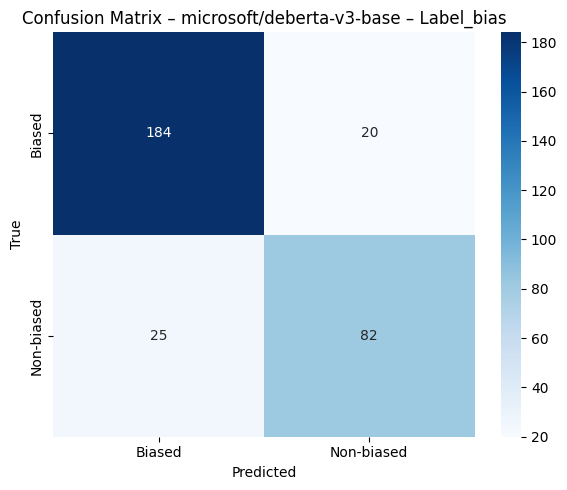

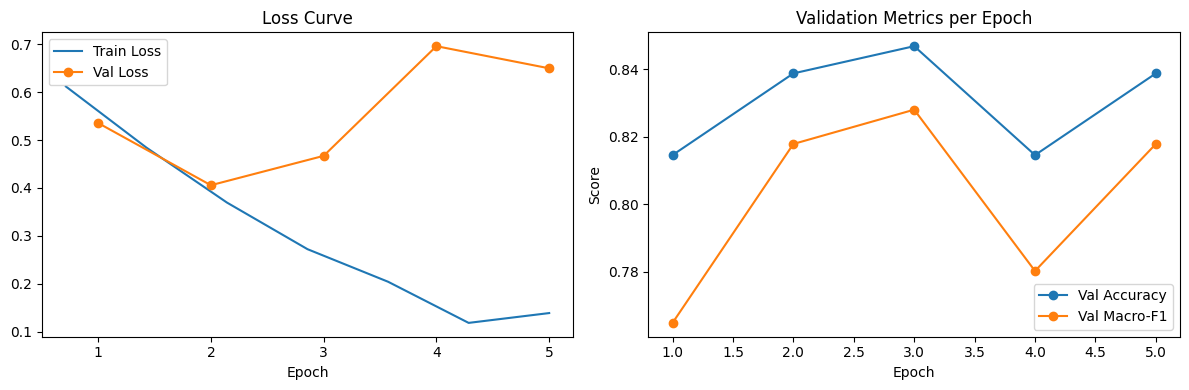

In [5]:
# =========================
# DeBERTa-v3-base (plain): Train + Visualize
# Updated for transformers v5: fp32 weights + mixed precision (AMP) + dynamic padding
# =========================
# NOTE: no `pip install -U` in this cell. Upgrading packages in the same cell as the
# imports is what broke pyarrow. If you ever need to install something, do it in its
# own cell once, then Runtime -> Restart session, then run this cell.

import gc
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    set_seed,
)

# ---------- Free GPU memory from earlier runs (makes this cell safe to re-run) ----------
for _v in ["trainer", "model", "mdl"]:
    globals().pop(_v, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---------- Config ----------
set_seed(SEED)
MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LEN = 256
EPOCHS = 5

# ---------- GPU + precision (picked automatically) ----------
HAS_GPU = torch.cuda.is_available()
USE_BF16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8   # A100 / L4 / H100
USE_FP16 = HAS_GPU and not USE_BF16                                  # T4 (no bf16 support)
print(f"GPU: {torch.cuda.get_device_name(0) if HAS_GPU else 'none'} | bf16={USE_BF16} | fp16={USE_FP16}")

# -------------------------
# DATA: shared train / val / test split (set in the SHARED cell, identical for every model)
# -------------------------
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
print("Classes:", list(le.classes_))
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)} | split id: {SPLIT_ID}")
print("Input includes annotator words (biased_words4):", USE_BIASED_WORDS)

# ---------- Dataset (no padding here -> DataCollatorWithPadding pads per batch = faster) ----------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(texts):
    return tokenizer(texts, truncation=True, max_length=MAX_LEN)

class TextClsDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenize(texts)
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = int(self.labels[idx])
        return item

train_ds = TextClsDataset(X_train, y_train)
val_ds   = TextClsDataset(X_val, y_val)
test_ds  = TextClsDataset(X_test, y_test)
collator = DataCollatorWithPadding(tokenizer)

# ---------- Model ----------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    dtype=torch.float32,   # REQUIRED: transformers v5 otherwise loads this checkpoint in fp16 -> NaN loss
)
print("Model dtype:", model.dtype)   # must be torch.float32 (AMP handles the speed-up)
assert model.dtype == torch.float32, "Model must be loaded in float32"

# ---------- Metrics ----------
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }

# ---------- TrainingArguments ----------
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="best",           # only saves when val accuracy improves (faster)
    save_total_limit=1,
    save_only_model=True,           # skip optimizer state -> faster, smaller checkpoints
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",
    bf16=USE_BF16,                  # mixed precision: weights stay fp32, math runs in half precision
    fp16=USE_FP16,
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,            # validation set, not test
    data_collator=collator,
    compute_metrics=compute_metrics,
)

# ---------- Train ----------
trainer.train()

logs = trainer.state.log_history
if any(np.isnan(x["eval_loss"]) for x in logs if "eval_loss" in x):
    print("\n!!! Validation loss became NaN. Set USE_BF16 = USE_FP16 = False in the GPU section and rerun.\n")

# ---------- Predict on the untouched TEST set ----------
preds = trainer.predict(test_ds)
y_pred = np.argmax(preds.predictions, axis=1)

acc = accuracy_score(y_test, y_pred)
mf1 = f1_score(y_test, y_pred, average="macro")

print("\nTEST Accuracy:", acc)
print("TEST Macro-F1:", mf1)
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
record_result("DeBERTa-v3-base (plain)", y_test, y_pred)

# ---------- Visualization: Confusion Matrix ----------
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix – {MODEL_NAME} – {TARGET}")
plt.tight_layout()
plt.show()

# ---------- Visualization: Training curves (both against epoch so they line up) ----------
train_pts = [(x["epoch"], x["loss"]) for x in logs if "loss" in x]
eval_pts  = [x for x in logs if "eval_loss" in x]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
if train_pts:
    plt.plot(*zip(*train_pts), label="Train Loss")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_loss"] for x in eval_pts], marker="o", label="Val Loss")
plt.xlabel("Epoch"); plt.legend(); plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot([x["epoch"] for x in eval_pts], [x["eval_accuracy"] for x in eval_pts], marker="o", label="Val Accuracy")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_macro_f1"] for x in eval_pts], marker="o", label="Val Macro-F1")
plt.xlabel("Epoch"); plt.ylabel("Score"); plt.legend(); plt.title("Validation Metrics per Epoch")

plt.tight_layout()
plt.show()

In [6]:
# =========================
# SAVE plain DeBERTa (best model: TEST accuracy ~0.855, macro-F1 ~0.838) to Google Drive
# Uses `trainer`, `tokenizer`, `acc`, `mf1` from the cell above.
# =========================
import os, json, transformers

SAVE_DIR_PLAIN = "/content/drive/MyDrive/truthlens/model_deberta_plain"
os.makedirs(SAVE_DIR_PLAIN, exist_ok=True)

assert type(trainer.model).__name__.startswith("DebertaV2"), "Run the plain DeBERTa cell first"
trainer.save_model(SAVE_DIR_PLAIN)          # best epoch (load_best_model_at_end=True)
tokenizer.save_pretrained(SAVE_DIR_PLAIN)   # includes tokenizer.json (needed for word highlighting)
save_run_info(SAVE_DIR_PLAIN)
with open(f"{SAVE_DIR_PLAIN}/test_metrics.json", "w") as f:
    json.dump({"accuracy": float(acc), "macro_f1": float(mf1), "split_id": SPLIT_ID,
               "classes": [str(c) for c in le.classes_],
               "transformers_version": transformers.__version__}, f, indent=2)

print("Saved to", SAVE_DIR_PLAIN)
print(sorted(os.listdir(SAVE_DIR_PLAIN)))
print("TEST accuracy:", round(float(acc), 4), "| macro-F1:", round(float(mf1), 4))
print("transformers version (install the same on your laptop):", transformers.__version__)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/truthlens/model_deberta_plain
['config.json', 'model.safetensors', 'test_metrics.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'truthlens_run_info.json']
TEST accuracy: 0.8553 | macro-F1: 0.8379
transformers version (install the same on your laptop): 5.21.0


## DeBERTa-v3-base (tuned)
Weighted loss, warmup + cosine schedule, layer-wise learning rates. Saved for the ensemble.

GPU: Tesla T4 | bf16=False | fp16=True
Classes: ['Biased', 'Non-biased']
Train: 1116 | Val: 124 | Test: 311 | split id: 3d637336
Input includes annotator words (biased_words4): False
Class weights: {'Biased': 0.761, 'Non-biased': 1.457}


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.696773,0.686005,0.741935,0.731892
2,0.676490,0.468781,0.838710,0.817808
3,0.360050,0.408855,0.782258,0.769659
4,0.287958,0.559995,0.838710,0.817808


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TEST Accuracy: 0.7909967845659164
TEST Macro-F1: 0.7668961381902883

Classification report:
               precision    recall  f1-score   support

      Biased       0.84      0.85      0.84       204
  Non-biased       0.70      0.68      0.69       107

    accuracy                           0.79       311
   macro avg       0.77      0.77      0.77       311
weighted avg       0.79      0.79      0.79       311



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model to /content/model_deberta


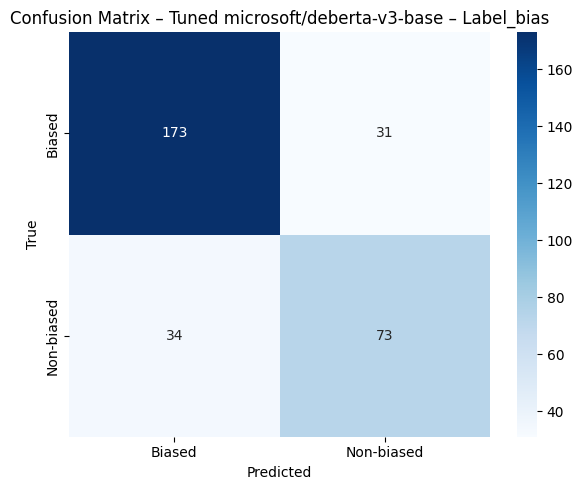

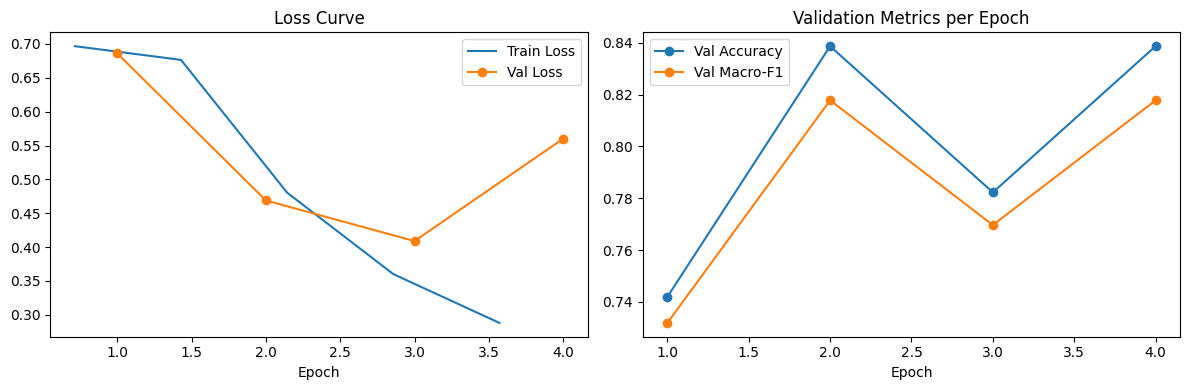

In [7]:
# =========================
# Tuned DeBERTa-v3-base (saved to /content/model_deberta for the ensemble)
# EarlyStopping + WeightedLoss + Warmup/Cosine + Layerwise LR decay
# Updated for transformers v5: fp32 weights + mixed precision (AMP) + dynamic padding
# =========================
# NOTE: no `pip install -U` in this cell. Upgrading packages in the same cell as the
# imports is what broke pyarrow. If you ever need to install something, do it in its
# own cell once, then Runtime -> Restart session, then run this cell.

import gc
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed,
    EarlyStoppingCallback, DataCollatorWithPadding,
    get_cosine_schedule_with_warmup,
)

# -------------------------
# Free GPU memory from earlier runs (makes this cell safe to re-run)
# -------------------------
for _v in ["trainer", "model", "mdl"]:
    globals().pop(_v, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

set_seed(SEED)

# -------------------------
# CONFIG
# -------------------------

MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LEN = 320                    # with dynamic padding, batches are only as long as their longest sentence
EPOCHS = 10                      # early stopping will stop earlier
BATCH_TRAIN = 16
BATCH_EVAL = 32
LR_HEAD = 2.2e-5                 # head LR (lower layers get smaller LRs via layer-wise decay)
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
PATIENCE = 2                     # early stop if no improvement for 2 evals
SAVE_DIR = "/content/model_deberta"   # the ensemble cell loads the model from here

# -------------------------
# GPU + precision (picked automatically)
# -------------------------
HAS_GPU = torch.cuda.is_available()
USE_BF16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8   # A100 / L4 / H100
USE_FP16 = HAS_GPU and not USE_BF16                                  # T4 (no bf16 support)
device = torch.device("cuda" if HAS_GPU else "cpu")
print(f"GPU: {torch.cuda.get_device_name(0) if HAS_GPU else 'none'} | bf16={USE_BF16} | fp16={USE_FP16}")

# -------------------------
# DATA: shared train / val / test split (set in the SHARED cell, identical for every model)
# -------------------------
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
print("Classes:", list(le.classes_))
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)} | split id: {SPLIT_ID}")
print("Input includes annotator words (biased_words4):", USE_BIASED_WORDS)

# -------------------------
# TOKENIZE (no padding here -> DataCollatorWithPadding pads per batch = faster)
# -------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(texts):
    return tokenizer(texts, truncation=True, max_length=MAX_LEN)

class TextDS(Dataset):
    def __init__(self, texts, y):
        self.enc, self.y = tokenize(texts), y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.y[i])
        return item

train_ds = TextDS(X_train, y_train)
val_ds   = TextDS(X_val, y_val)
test_ds  = TextDS(X_test, y_test)
collator = DataCollatorWithPadding(tokenizer)

# -------------------------
# CLASS WEIGHTS (from the training split only)
# -------------------------
classes = np.unique(y_train)
cw = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = torch.tensor(cw, dtype=torch.float32)
print("Class weights:", {le.classes_[int(c)]: round(float(w), 3) for c, w in zip(classes, cw)})

# -------------------------
# MODEL
# -------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    dtype=torch.float32,   # REQUIRED: transformers v5 otherwise loads this checkpoint in fp16 -> NaN loss
)
print("Model dtype:", model.dtype)   # must be torch.float32 (AMP handles the speed-up)
assert model.dtype == torch.float32, "Model must be loaded in float32"

# -------------------------
# Layer-wise LR decay parameter groups
# -------------------------
def layerwise_lr_decay_params(model, base_lr, head_lr, decay=0.90, weight_decay=WEIGHT_DECAY):
    """
    Lower layers get smaller LR; top layers + classifier get larger LR.
    Works for DeBERTa-v3 (DebertaV2Model) naming patterns.
    """
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]

    # count encoder layers (DeBERTa-v3 has encoder.layer.{i})
    layer_ids = set()
    for n, _ in model.named_parameters():
        if "encoder.layer." in n:
            idx = n.split("encoder.layer.")[1].split(".")[0]
            if idx.isdigit():
                layer_ids.add(int(idx))
    num_layers = (max(layer_ids) + 1) if layer_ids else None

    def lr_for(name):
        if "classifier" in name or "pooler" in name:
            return head_lr
        if num_layers is None:
            return base_lr
        if "encoder.layer." in name:
            lid = int(name.split("encoder.layer.")[1].split(".")[0])
            return base_lr * (decay ** (num_layers - 1 - lid))   # deeper layer -> higher lr
        return base_lr * (decay ** num_layers)                   # embeddings + others

    grouped = {}
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        lr = lr_for(name)
        wd = 0.0 if any(nd in name for nd in no_decay) else weight_decay
        grouped.setdefault((lr, wd), []).append(param)

    return [{"params": p, "lr": lr, "weight_decay": wd} for (lr, wd), p in grouped.items()]

# -------------------------
# Custom Trainer: weighted loss + layer-wise LR + cosine schedule
# -------------------------
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        logits = outputs.logits.float()   # loss in fp32 even under mixed precision
        loss = nn.functional.cross_entropy(logits, labels, weight=class_weights.to(logits.device))
        return (loss, outputs) if return_outputs else loss

    def create_optimizer(self, model=None):   # v5 may pass `model` -> must accept it
        if self.optimizer is None:
            opt_model = model if model is not None else self.model
            params = layerwise_lr_decay_params(opt_model, base_lr=LR_HEAD / 2.0, head_lr=LR_HEAD, decay=0.90)
            self.optimizer = torch.optim.AdamW(params)
        return self.optimizer

    def create_scheduler(self, num_training_steps, optimizer=None):
        if self.lr_scheduler is None:
            optimizer = optimizer or self.optimizer
            warmup_steps = int(WARMUP_RATIO * num_training_steps)
            self.lr_scheduler = get_cosine_schedule_with_warmup(
                optimizer, num_warmup_steps=warmup_steps, num_training_steps=num_training_steps
            )
        return self.lr_scheduler

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }

# -------------------------
# Training args
# -------------------------
args = TrainingArguments(
    output_dir="./results_tuned",
    eval_strategy="epoch",
    save_strategy="best",           # only saves when val accuracy improves (faster)
    save_total_limit=1,
    save_only_model=True,           # skip optimizer state -> much faster, smaller checkpoints
    learning_rate=LR_HEAD,          # for logging only; real LRs come from create_optimizer
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    num_train_epochs=EPOCHS,
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    report_to="none",
    bf16=USE_BF16,                  # mixed precision: weights stay fp32, math runs in half precision
    fp16=USE_FP16,
    seed=42,
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,            # validation set, not test
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

# -------------------------
# Train
# -------------------------
trainer.train()

logs = trainer.state.log_history
if any(np.isnan(x["eval_loss"]) for x in logs if "eval_loss" in x):
    print("\n!!! Validation loss became NaN. Set USE_BF16 = USE_FP16 = False in the GPU section and rerun.\n")

# -------------------------
# Final evaluation on the untouched TEST set
# -------------------------
pred = trainer.predict(test_ds)
y_pred = np.argmax(pred.predictions, axis=1)

acc = accuracy_score(y_test, y_pred)
mf1 = f1_score(y_test, y_pred, average="macro")

print("\nTEST Accuracy:", acc)
print("TEST Macro-F1:", mf1)
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
record_result("DeBERTa-v3-base (tuned)", y_test, y_pred)

# Save best model + tokenizer for the ensemble cell
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
save_run_info(SAVE_DIR)   # lets the ensemble cell check settings match
print("Saved best model to", SAVE_DIR)

# -------------------------
# Confusion matrix
# -------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix – Tuned {MODEL_NAME} – {TARGET}")
plt.tight_layout()
plt.show()

# -------------------------
# Training curves (both plotted against epoch so they line up)
# -------------------------
train_pts = [(x["epoch"], x["loss"]) for x in logs if "loss" in x]
eval_pts  = [x for x in logs if "eval_loss" in x]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
if train_pts:
    plt.plot(*zip(*train_pts), label="Train Loss")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_loss"] for x in eval_pts], marker="o", label="Val Loss")
plt.xlabel("Epoch"); plt.legend(); plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot([x["epoch"] for x in eval_pts], [x["eval_accuracy"] for x in eval_pts], marker="o", label="Val Accuracy")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_macro_f1"] for x in eval_pts], marker="o", label="Val Macro-F1")
plt.xlabel("Epoch"); plt.legend(); plt.title("Validation Metrics per Epoch")
plt.tight_layout()
plt.show()

### Optional checks
Run right after the tuned DeBERTa cell if you ever see NaN losses.

In [8]:
# =========================
# DeBERTa Numerical Stability Check
# =========================

import torch
import transformers
import numpy as np

print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nModel:", MODEL_NAME)

print("\nModel type:", type(model).__name__)

print("\nModel device:", next(model.parameters()).device)

print("\nChecking training labels:")

print("Unique labels:", np.unique(y_train))

print("Label counts:", np.bincount(y_train))

# Check whether model parameters contain NaN or infinity

bad_params = []

for name, param in model.named_parameters():

    if not torch.isfinite(param).all():

        bad_params.append(name)

print("\nInvalid model parameters:", bad_params)

# Check one training sample

# Check one training sample (same tensor conversion the Trainer uses)
device = next(model.parameters()).device

batch = collator([train_ds[0]])                       # list -> padded tensors, batch size 1
batch = {k: v.to(device) for k, v in batch.items()}
labels = batch.pop("labels")
inputs = batch

model.eval()

with torch.no_grad():

    outputs = model(**inputs)

    logits = outputs.logits

    loss = torch.nn.functional.cross_entropy(
        logits,
        labels
    )

print("\nSample logits:", logits)

print("\nSample loss:", loss.item())

print("\nLogits finite:", torch.isfinite(logits).all().item())

print("\nLoss finite:", torch.isfinite(loss).item())

print("\nPredicted class:", logits.argmax(dim=1).item())

print("\nActual class:", labels.item())

# Check all training labels and text

print("\nTraining dataset size:", len(train_ds))

print("Validation dataset size:", len(val_ds))

print("Test dataset size:", len(test_ds))

print("\nDiagnostic completed.")

Transformers version: 5.21.0
PyTorch version: 2.11.0+cu130
CUDA available: True

Model: microsoft/deberta-v3-base

Model type: DebertaV2ForSequenceClassification

Model device: cuda:0

Checking training labels:
Unique labels: [0 1]
Label counts: [733 383]

Invalid model parameters: []

Sample logits: tensor([[ 0.7788, -0.7310]], device='cuda:0')

Sample loss: 1.7094045877456665

Logits finite: True

Loss finite: True

Predicted class: 0

Actual class: 1

Training dataset size: 1116
Validation dataset size: 124
Test dataset size: 311

Diagnostic completed.


In [9]:
# Check model precision

print("Model parameter dtype:")

for name, param in model.named_parameters():

    print(name, param.dtype)

    break

print("\nModel config:")
print("num_labels:", model.config.num_labels)

print("\nClassifier:")
print(model.classifier)

Model parameter dtype:
deberta.embeddings.word_embeddings.weight torch.float32

Model config:
num_labels: 2

Classifier:
Linear(in_features=768, out_features=2, bias=True)


## Explainable AI (Captum)
Run right after the tuned DeBERTa cell.

Picked indices: [np.int64(0), np.int64(1), np.int64(13), np.int64(14)] | correct: 246 wrong: 65
Example #0
TRUE: Biased | PRED: Biased
TEXT: Finally, he launched into a meandering rant about Biden, suggesting that under the Obama administration, nothing was done to fix policing in the United States. While the previous administration surely didn’t do enough, and Biden himself has contributed to the criminal justice problems in the country, Trump completely ignored the fact that the Obama Justice Department actually did take significant  ...


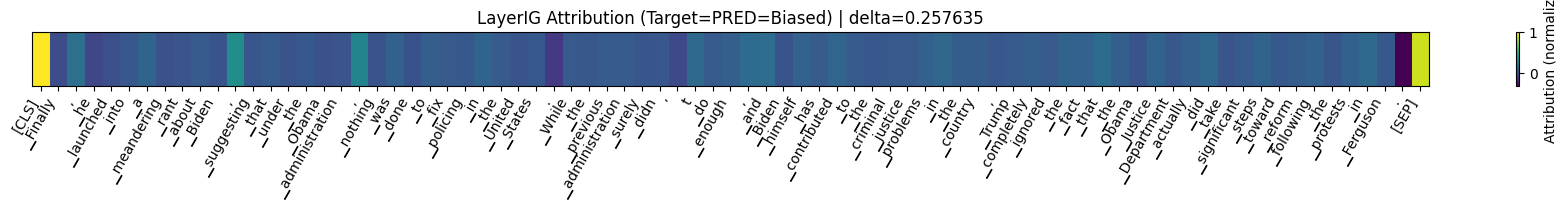

Example #1
TRUE: Biased | PRED: Biased
TEXT: Hillary’s letter is painful. It’s riddled with stilted speech and a weak attempt to use swear words like that other future has-been who at least can kind of skateboard and pretend to air drum. Whether or not you agreed with Trump’s approach, at least his fondness for cuss words is authentic, something Hilldog struggles with.


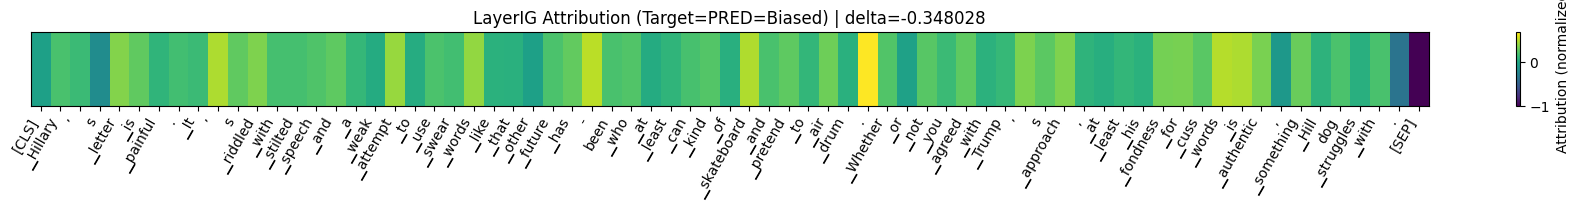

Example #13
TRUE: Non-biased | PRED: Biased
TEXT: When carrying a firearm, you have the ultimate power of force in your control.


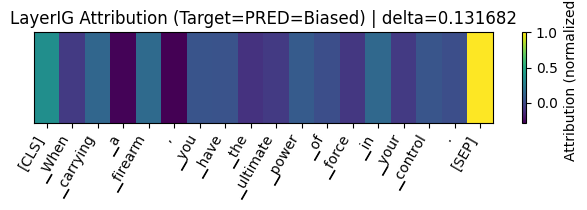

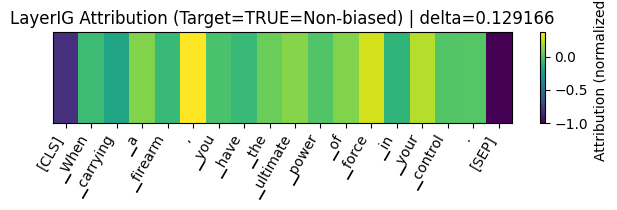

Example #14
TRUE: Non-biased | PRED: Biased
TEXT: Abortion rights advocates worry this could make it more difficult for women to get access to abortion through the courts or that it could lead to criminalizing contraception or in-vitro fertilization.


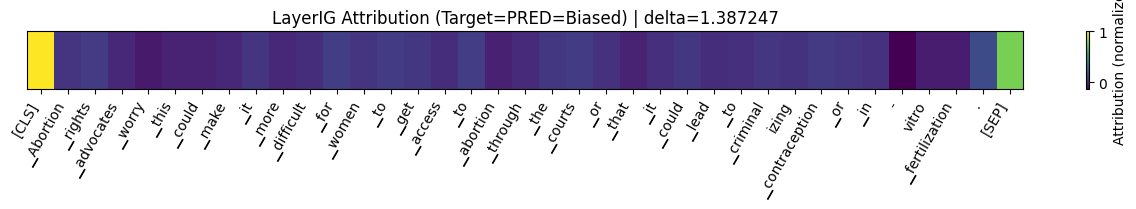

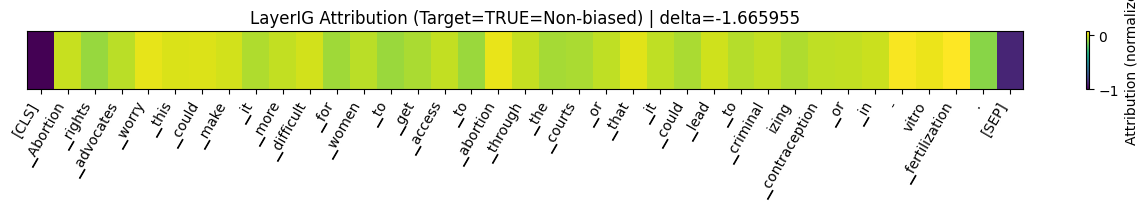

In [10]:
# =========================
# XAI for DeBERTa (Captum)
# Run right AFTER the tuned DeBERTa cell: it explains whichever `model` was trained last
# =========================

# Install captum without touching numpy
!pip -q install "captum>=0.7.0" --no-deps

import torch
import numpy as np
import matplotlib.pyplot as plt

from captum.attr import LayerIntegratedGradients

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# ---- Forward for Captum: returns logits ----
def forward_func(input_ids, attention_mask):
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
    return outputs.logits

# ---- Layer to attribute: word embeddings (best practice) ----
# Works for DeBERTaV2/DeBERTaV3 models
emb_layer = model.deberta.embeddings.word_embeddings
lig = LayerIntegratedGradients(forward_func, emb_layer)

def explain_text(text, target_label_idx=None, max_len=256, n_steps=32):
    enc = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=max_len,
        return_tensors="pt"
    )
    input_ids = enc["input_ids"].to(device)
    attn_mask = enc["attention_mask"].to(device)

    # Predict
    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
        pred_idx = int(torch.argmax(logits, dim=1).item())

    if target_label_idx is None:
        target_label_idx = pred_idx

    # Baseline: PAD tokens
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id).to(device)

    # Layer IG attributions (on embedding layer)
    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attn_mask,),
        target=target_label_idx,
        return_convergence_delta=True,
        n_steps=n_steps
    )

    # attributions: [1, seq_len, hidden] -> reduce hidden -> [seq_len]
    token_attr = attributions.sum(dim=-1).squeeze(0)

    # mask padding
    token_attr = token_attr * attn_mask.squeeze(0)

    # normalize
    token_attr = token_attr.detach().cpu().numpy()
    token_attr = token_attr / (np.max(np.abs(token_attr)) + 1e-9)

    tokens = tokenizer.convert_ids_to_tokens(input_ids.squeeze(0).detach().cpu().tolist())
    valid_len = int(attn_mask.sum().item())
    tokens = tokens[:valid_len]
    token_attr = token_attr[:valid_len]

    pred_name = le.inverse_transform([pred_idx])[0]
    tgt_name  = le.inverse_transform([target_label_idx])[0]

    return tokens, token_attr, pred_idx, target_label_idx, pred_name, tgt_name, float(delta.detach().cpu().item())

def show_token_heatmap(tokens, scores, title="Token attribution (LayerIG)"):
    plt.figure(figsize=(min(18, 0.35*len(tokens)), 2.2))
    plt.imshow(scores[np.newaxis, :], aspect="auto")
    plt.yticks([])
    plt.xticks(range(len(tokens)), tokens, rotation=60, ha="right", fontsize=10)
    plt.colorbar(label="Attribution (normalized)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# ---- Pick examples: 2 correct + 2 incorrect (if available) ----
indices = np.arange(len(X_test))  # <-- FIXED
correct = indices[np.array(y_pred) == np.array(y_test)]
wrong   = indices[np.array(y_pred) != np.array(y_test)]

picked = []
picked += list(correct[:2]) if len(correct) >= 2 else list(correct)
picked += list(wrong[:2])   if len(wrong) >= 2 else list(wrong)

print("Picked indices:", picked, "| correct:", len(correct), "wrong:", len(wrong))

for i in picked:
    text = X_test[i]
    true_idx = int(y_test[i])
    pred_idx = int(y_pred[i])

    print("="*95)
    print(f"Example #{i}")
    print(f"TRUE: {le.inverse_transform([true_idx])[0]} | PRED: {le.inverse_transform([pred_idx])[0]}")
    print("TEXT:", text[:400] + (" ..." if len(text) > 400 else ""))

    # Explain predicted class
    tokens, scores, _, _, pred_name, _, delta = explain_text(text, target_label_idx=pred_idx, max_len=256, n_steps=32)
    show_token_heatmap(tokens, scores, title=f"LayerIG Attribution (Target=PRED={pred_name}) | delta={delta:.6f}")

    # If wrong, also explain true class
    if pred_idx != true_idx:
        tokens2, scores2, _, _, _, tgt_name, delta2 = explain_text(text, target_label_idx=true_idx, max_len=256, n_steps=32)
        show_token_heatmap(tokens2, scores2, title=f"LayerIG Attribution (Target=TRUE={tgt_name}) | delta={delta2:.6f}")


## DeBERTa-v3-base variant (label smoothing)

GPU: Tesla T4 | bf16=False | fp16=True
Classes: ['Biased', 'Non-biased']
Train: 1116 | Val: 124 | Test: 311 | split id: 3d637336
Input includes annotator words (biased_words4): False
Class weights: {'Biased': 0.761, 'Non-biased': 1.457}


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.693376,0.694065,0.346774,0.257485
2,0.694693,0.633803,0.709677,0.708464
3,0.532142,0.517049,0.790323,0.782162
4,0.480329,0.525183,0.822581,0.804192
5,0.430063,0.528601,0.822581,0.804192
6,0.380329,0.582062,0.814516,0.794154
7,0.356688,0.625085,0.814516,0.791749


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TEST Accuracy: 0.8295819935691319
TEST Macro-F1: 0.8099306972936198

Classification report:
               precision    recall  f1-score   support

      Biased       0.86      0.88      0.87       204
  Non-biased       0.76      0.74      0.75       107

    accuracy                           0.83       311
   macro avg       0.81      0.81      0.81       311
weighted avg       0.83      0.83      0.83       311



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model to /content/model_deberta_v2


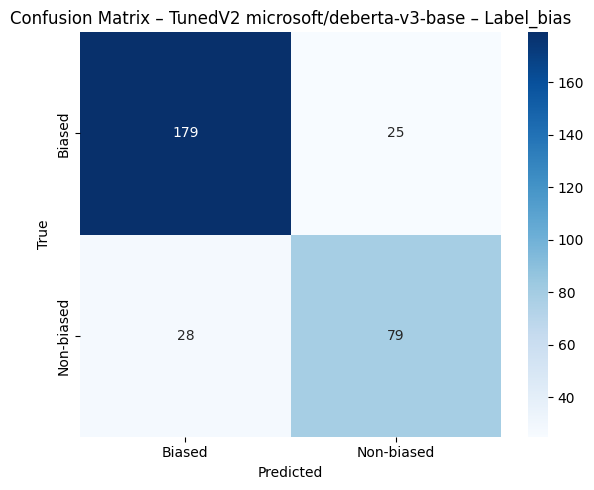

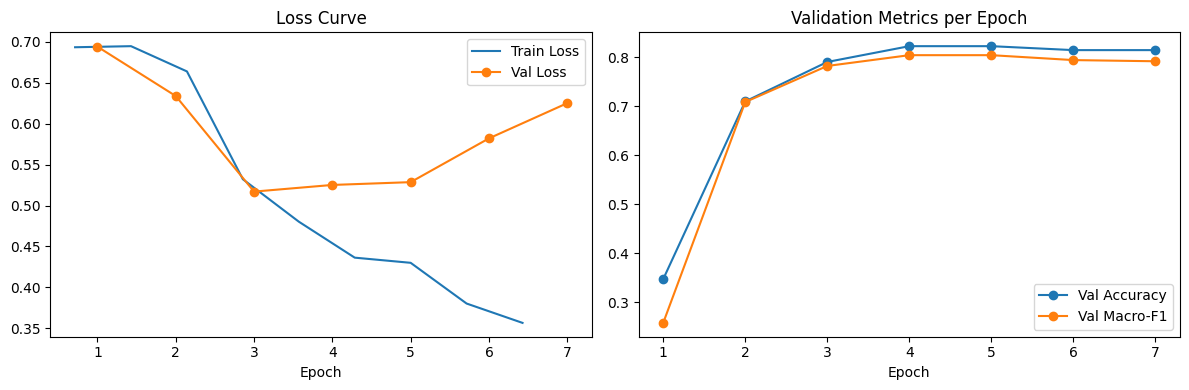

In [11]:
# =========================
# DeBERTa-v3-base variant: label smoothing, best epoch by val macro-F1
# Best by Macro-F1 + Label Smoothing + Longer context + Slight LR/Warmup tweaks
# Updated for transformers v5: fp32 weights + mixed precision (AMP) + dynamic padding
# =========================
# NOTE: no `pip install -U` in this cell. Upgrading packages in the same cell as the
# imports is what broke pyarrow. If you ever need to install something, do it in its
# own cell once, then Runtime -> Restart session, then run this cell.

import gc
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed,
    EarlyStoppingCallback, DataCollatorWithPadding,
    get_cosine_schedule_with_warmup,
)

# -------------------------
# Free GPU memory from earlier runs (makes this cell safe to re-run)
# -------------------------
for _v in ["trainer", "model", "mdl"]:
    globals().pop(_v, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

set_seed(SEED)

# -------------------------
# CONFIG
# -------------------------

MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LEN = 256                      # MBIC sentences are at most ~130 tokens, so nothing is cut
EPOCHS = 14                        # early stopping will likely stop earlier
BATCH_TRAIN = 16
BATCH_EVAL = 32

LR_HEAD = 1.6e-5                   # slightly lower for generalization
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.12                # a bit more warmup helps stability
PATIENCE = 3                       # allow more room before early stop
LABEL_SMOOTHING = 0.08             # reduces overconfidence
SAVE_DIR = "/content/model_deberta_v2"   # separate folder so it doesn't overwrite cell 2's model

# -------------------------
# GPU + precision (picked automatically)
# -------------------------
HAS_GPU = torch.cuda.is_available()
USE_BF16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8   # A100 / L4 / H100
USE_FP16 = HAS_GPU and not USE_BF16                                  # T4 (no bf16 support)
print(f"GPU: {torch.cuda.get_device_name(0) if HAS_GPU else 'none'} | bf16={USE_BF16} | fp16={USE_FP16}")

# -------------------------
# DATA: shared train / val / test split (set in the SHARED cell, identical for every model)
# -------------------------
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
print("Classes:", list(le.classes_))
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)} | split id: {SPLIT_ID}")
print("Input includes annotator words (biased_words4):", USE_BIASED_WORDS)

# -------------------------
# TOKENIZE (no padding here -> DataCollatorWithPadding pads per batch = faster)
# -------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(texts):
    return tokenizer(texts, truncation=True, max_length=MAX_LEN)

class TextDS(Dataset):
    def __init__(self, texts, y):
        self.enc, self.y = tokenize(texts), y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.y[i])
        return item

train_ds = TextDS(X_train, y_train)
val_ds   = TextDS(X_val, y_val)
test_ds  = TextDS(X_test, y_test)
collator = DataCollatorWithPadding(tokenizer)

# -------------------------
# CLASS WEIGHTS (from the training split only)
# -------------------------
classes = np.unique(y_train)
cw = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = torch.tensor(cw, dtype=torch.float32)
print("Class weights:", {le.classes_[int(c)]: round(float(w), 3) for c, w in zip(classes, cw)})

# -------------------------
# MODEL
# -------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    dtype=torch.float32,   # REQUIRED: transformers v5 otherwise loads this checkpoint in fp16 -> NaN / FP16 gradient errors
)
print("Model dtype:", model.dtype)   # must be torch.float32 (AMP handles the speed-up)
assert model.dtype == torch.float32, "Model must be loaded in float32"

# -------------------------
# Layer-wise LR decay parameter groups
# -------------------------
def layerwise_lr_decay_params(model, base_lr, head_lr, decay=0.90, weight_decay=WEIGHT_DECAY):
    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]

    # count encoder layers (DeBERTa-v3 has encoder.layer.{i})
    layer_ids = set()
    for n, _ in model.named_parameters():
        if "encoder.layer." in n:
            idx = n.split("encoder.layer.")[1].split(".")[0]
            if idx.isdigit():
                layer_ids.add(int(idx))
    num_layers = (max(layer_ids) + 1) if layer_ids else None

    def lr_for(name):
        if "classifier" in name or "pooler" in name:
            return head_lr
        if num_layers is None:
            return base_lr
        if "encoder.layer." in name:
            lid = int(name.split("encoder.layer.")[1].split(".")[0])
            return base_lr * (decay ** (num_layers - 1 - lid))   # deeper layer -> higher lr
        return base_lr * (decay ** num_layers)                   # embeddings + others

    grouped = {}
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        lr = lr_for(name)
        wd = 0.0 if any(nd in name for nd in no_decay) else weight_decay
        grouped.setdefault((lr, wd), []).append(param)

    return [{"params": p, "lr": lr, "weight_decay": wd} for (lr, wd), p in grouped.items()]

# -------------------------
# Custom Trainer: weighted loss + label smoothing + layer-wise LR + cosine schedule
# -------------------------
class WeightedSmoothTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        logits = outputs.logits.float()   # loss in fp32 even under mixed precision

        # Weighted CE with label smoothing (same formula as before)
        num_classes = logits.size(-1)
        log_probs = torch.log_softmax(logits, dim=-1)
        with torch.no_grad():
            true_dist = torch.full_like(log_probs, LABEL_SMOOTHING / (num_classes - 1))
            true_dist.scatter_(1, labels.unsqueeze(1), 1.0 - LABEL_SMOOTHING)

        w = class_weights.to(logits.device)[labels]          # per-sample class weight
        loss = (-(true_dist * log_probs).sum(dim=1) * w).mean()

        return (loss, outputs) if return_outputs else loss

    def create_optimizer(self, model=None):   # v5 may pass `model` -> must accept it
        if self.optimizer is None:
            opt_model = model if model is not None else self.model
            params = layerwise_lr_decay_params(opt_model, base_lr=LR_HEAD / 2.2, head_lr=LR_HEAD, decay=0.90)
            self.optimizer = torch.optim.AdamW(params)
        return self.optimizer

    def create_scheduler(self, num_training_steps, optimizer=None):
        if self.lr_scheduler is None:
            optimizer = optimizer or self.optimizer
            warmup_steps = int(WARMUP_RATIO * num_training_steps)
            self.lr_scheduler = get_cosine_schedule_with_warmup(
                optimizer, num_warmup_steps=warmup_steps, num_training_steps=num_training_steps
            )
        return self.lr_scheduler

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }

# -------------------------
# Training args (best model by Macro-F1)
# -------------------------
args = TrainingArguments(
    output_dir="./results_tuned_v2",
    eval_strategy="epoch",
    save_strategy="best",           # only saves when val macro-F1 improves (faster)
    save_total_limit=1,
    save_only_model=True,           # skip optimizer state -> faster, smaller checkpoints
    learning_rate=LR_HEAD,          # for logging only; real LRs come from create_optimizer
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    num_train_epochs=EPOCHS,
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none",
    bf16=USE_BF16,                  # mixed precision: weights stay fp32, math runs in half precision
    fp16=USE_FP16,
    seed=42,
)

trainer = WeightedSmoothTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,            # validation set, not test
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

# -------------------------
# Train
# -------------------------
trainer.train()

logs = trainer.state.log_history
if any(np.isnan(x["eval_loss"]) for x in logs if "eval_loss" in x):
    print("\n!!! Validation loss became NaN. Set USE_BF16 = USE_FP16 = False in the GPU section and rerun.\n")

# -------------------------
# Final evaluation on the untouched TEST set
# -------------------------
pred = trainer.predict(test_ds)
y_pred = np.argmax(pred.predictions, axis=1)

acc = accuracy_score(y_test, y_pred)
mf1 = f1_score(y_test, y_pred, average="macro")

print("\nTEST Accuracy:", acc)
print("TEST Macro-F1:", mf1)
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
record_result("DeBERTa-v3-base (label smoothing)", y_test, y_pred)

# Save best model + tokenizer (for the ensemble cell)
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
save_run_info(SAVE_DIR)   # lets the ensemble cell check settings match
print("Saved best model to", SAVE_DIR)

# -------------------------
# Confusion matrix
# -------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix – TunedV2 {MODEL_NAME} – {TARGET}")
plt.tight_layout()
plt.show()

# -------------------------
# Training curves (both plotted against epoch so they line up)
# -------------------------
train_pts = [(x["epoch"], x["loss"]) for x in logs if "loss" in x]
eval_pts  = [x for x in logs if "eval_loss" in x]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
if train_pts:
    plt.plot(*zip(*train_pts), label="Train Loss")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_loss"] for x in eval_pts], marker="o", label="Val Loss")
plt.xlabel("Epoch"); plt.legend(); plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot([x["epoch"] for x in eval_pts], [x["eval_accuracy"] for x in eval_pts], marker="o", label="Val Accuracy")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_macro_f1"] for x in eval_pts], marker="o", label="Val Macro-F1")
plt.xlabel("Epoch"); plt.legend(); plt.title("Validation Metrics per Epoch")
plt.tight_layout()
plt.show()

## RoBERTa-large

GPU: Tesla T4 | bf16=False | fp16=True
Classes: ['Biased', 'Non-biased']
Train: 1116 | Val: 124 | Test: 311 | split id: 3d637336
Input includes annotator words (biased_words4): False


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


TEST Accuracy: 0.8231511254019293
TEST Macro-F1: 0.7988995614705433

Classification report:
               precision    recall  f1-score   support

      Biased       0.85      0.89      0.87       204
  Non-biased       0.77      0.69      0.73       107

    accuracy                           0.82       311
   macro avg       0.81      0.79      0.80       311
weighted avg       0.82      0.82      0.82       311



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model to /content/model_roberta_large


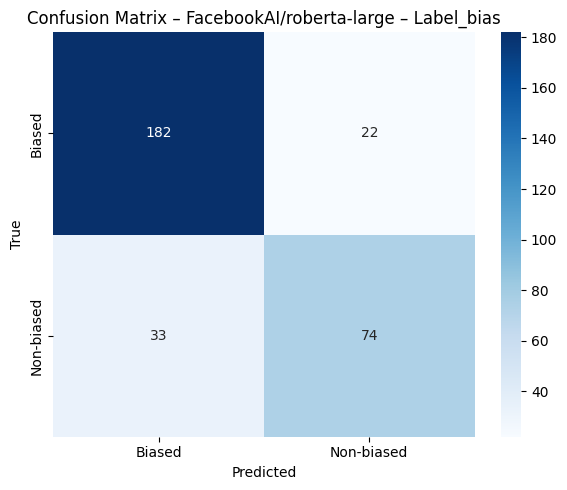

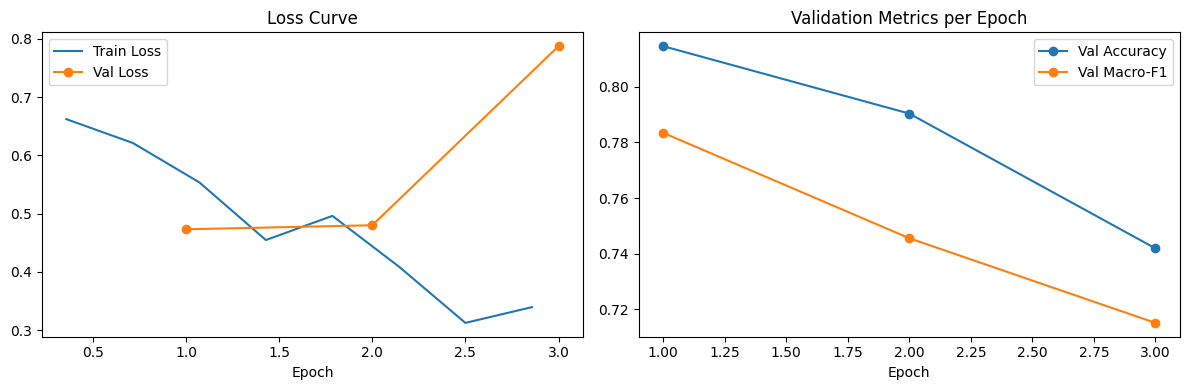

In [12]:
# =========================
# RoBERTa-large: same shared split, best epoch picked on VALIDATION, saved for the ensemble
# (no `pip install -U` here; install only in the setup cell)
# =========================
import gc
import numpy as np, torch
from torch import nn
from torch.utils.data import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed,
    EarlyStoppingCallback, DataCollatorWithPadding,
    get_cosine_schedule_with_warmup,
)

# -------------------------
# Free GPU memory from earlier runs (makes this cell safe to re-run)
# -------------------------
for _v in ["trainer", "model", "mdl"]:
    globals().pop(_v, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -------------------------
# CONFIG
# -------------------------
TRAIN_SEED = SEED               # change ONLY this (not SEED in the shared cell) if training collapses
set_seed(TRAIN_SEED)
MODEL_NAME = "FacebookAI/roberta-large"
MAX_LEN = 256                    # MBIC sentences are at most ~130 tokens, so nothing is cut
EPOCHS = 8
PATIENCE = 2
BATCH_TRAIN = 8                  # RoBERTa-large uses more VRAM; 8 fits a T4
BATCH_EVAL = 16
LR = 1.5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10              # warmup stops RoBERTa-large collapsing to one class on small data
LABEL_SMOOTHING = 0.06
SAVE_DIR = "/content/model_roberta_large"

# -------------------------
# GPU + precision (picked automatically)
# -------------------------
HAS_GPU = torch.cuda.is_available()
USE_BF16 = HAS_GPU and torch.cuda.get_device_capability()[0] >= 8   # A100 / L4 / H100
USE_FP16 = HAS_GPU and not USE_BF16                                  # T4 (no bf16 support)
print(f"GPU: {torch.cuda.get_device_name(0) if HAS_GPU else 'none'} | bf16={USE_BF16} | fp16={USE_FP16}")

# -------------------------
# DATA: shared train / val / test split (set in the SHARED cell, identical for every model)
# -------------------------
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
print("Classes:", list(le.classes_))
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)} | split id: {SPLIT_ID}")
print("Input includes annotator words (biased_words4):", USE_BIASED_WORDS)

# -------------------------
# TOKENIZE (no padding here -> DataCollatorWithPadding pads per batch)
# -------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(texts):
    return tokenizer(texts, truncation=True, max_length=MAX_LEN)

class TextDS(Dataset):
    def __init__(self, texts, y):
        self.enc, self.y = tokenize(texts), y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.y[i])
        return item

train_ds = TextDS(X_train, y_train)
val_ds   = TextDS(X_val, y_val)
test_ds  = TextDS(X_test, y_test)
collator = DataCollatorWithPadding(tokenizer)

# -------------------------
# MODEL (fp32 weights; mixed precision handles the speed-up)
# -------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    dtype=torch.float32,
)
print("Model dtype:", model.dtype)
assert model.dtype == torch.float32, "Model must be loaded in float32"

# -------------------------
# Trainer: label-smoothed loss + cosine schedule with warmup
# -------------------------
class SmoothTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        logits = outputs.logits.float()   # loss in fp32 even under mixed precision
        loss = nn.functional.cross_entropy(logits, labels, label_smoothing=LABEL_SMOOTHING)
        return (loss, outputs) if return_outputs else loss

    def create_scheduler(self, num_training_steps, optimizer=None):
        if self.lr_scheduler is None:
            optimizer = optimizer or self.optimizer
            self.lr_scheduler = get_cosine_schedule_with_warmup(
                optimizer, num_warmup_steps=int(WARMUP_RATIO * num_training_steps),
                num_training_steps=num_training_steps)
        return self.lr_scheduler

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="./roberta_large_runs",
    eval_strategy="epoch",
    save_strategy="best",
    save_total_limit=1,
    save_only_model=True,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    num_train_epochs=EPOCHS,
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none",
    bf16=USE_BF16,
    fp16=USE_FP16,
    seed=TRAIN_SEED,
)

trainer = SmoothTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,            # validation set, not test
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

# -------------------------
# Train
# -------------------------
trainer.train()

logs = trainer.state.log_history
if any(np.isnan(x["eval_loss"]) for x in logs if "eval_loss" in x):
    print("\n!!! Validation loss became NaN. Set USE_BF16 = USE_FP16 = False in the GPU section and rerun.\n")

# -------------------------
# Final evaluation on the untouched TEST set
# -------------------------
pred = trainer.predict(test_ds)
y_pred = np.argmax(pred.predictions, axis=1)
if len(np.unique(y_pred)) == 1:
    print("\n!!! The model predicts only one class (training collapsed). Set TRAIN_SEED in this cell to another number (e.g. 7) and rerun.\n")

print("\nTEST Accuracy:", accuracy_score(y_test, y_pred))
print("TEST Macro-F1:", f1_score(y_test, y_pred, average="macro"))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
record_result("RoBERTa-large", y_test, y_pred)

# Save best model + tokenizer for the ensemble cell
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
save_run_info(SAVE_DIR)
print("Saved best model to", SAVE_DIR)

# -------------------------
# Confusion matrix + training curves
# -------------------------
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix – {MODEL_NAME} – {TARGET}")
plt.tight_layout()
plt.show()

train_pts = [(x["epoch"], x["loss"]) for x in logs if "loss" in x]
eval_pts  = [x for x in logs if "eval_loss" in x]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
if train_pts:
    plt.plot(*zip(*train_pts), label="Train Loss")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_loss"] for x in eval_pts], marker="o", label="Val Loss")
plt.xlabel("Epoch"); plt.legend(); plt.title("Loss Curve")
plt.subplot(1, 2, 2)
plt.plot([x["epoch"] for x in eval_pts], [x["eval_accuracy"] for x in eval_pts], marker="o", label="Val Accuracy")
plt.plot([x["epoch"] for x in eval_pts], [x["eval_macro_f1"] for x in eval_pts], marker="o", label="Val Macro-F1")
plt.xlabel("Epoch"); plt.legend(); plt.title("Validation Metrics per Epoch")
plt.tight_layout()
plt.show()

## Ensemble

Val: 124 | Test: 311 | split id: 3d637336 | words in input: False


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


DeBERTa and RoBERTa give the same label on 90.4% of test sentences.

=== DeBERTa (loaded) ===
Accuracy: 0.7909967845659164
Macro-F1: 0.7668961381902883
              precision    recall  f1-score   support

      Biased       0.84      0.85      0.84       204
  Non-biased       0.70      0.68      0.69       107

    accuracy                           0.79       311
   macro avg       0.77      0.77      0.77       311
weighted avg       0.79      0.79      0.79       311



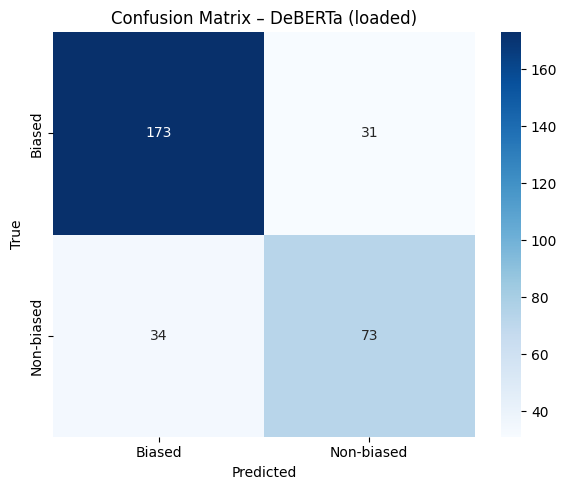


=== RoBERTa-large (loaded) ===
Accuracy: 0.8231511254019293
Macro-F1: 0.7988995614705433
              precision    recall  f1-score   support

      Biased       0.85      0.89      0.87       204
  Non-biased       0.77      0.69      0.73       107

    accuracy                           0.82       311
   macro avg       0.81      0.79      0.80       311
weighted avg       0.82      0.82      0.82       311



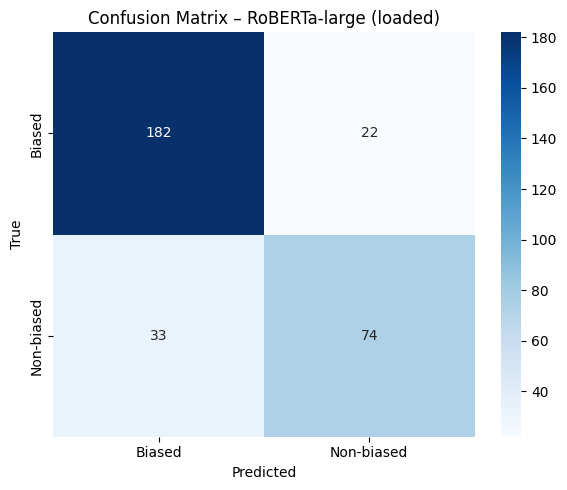


=== Soft vote (average) ===
Accuracy: 0.8070739549839229
Macro-F1: 0.7811708415423586
              precision    recall  f1-score   support

      Biased       0.84      0.88      0.86       204
  Non-biased       0.74      0.67      0.71       107

    accuracy                           0.81       311
   macro avg       0.79      0.78      0.78       311
weighted avg       0.80      0.81      0.80       311



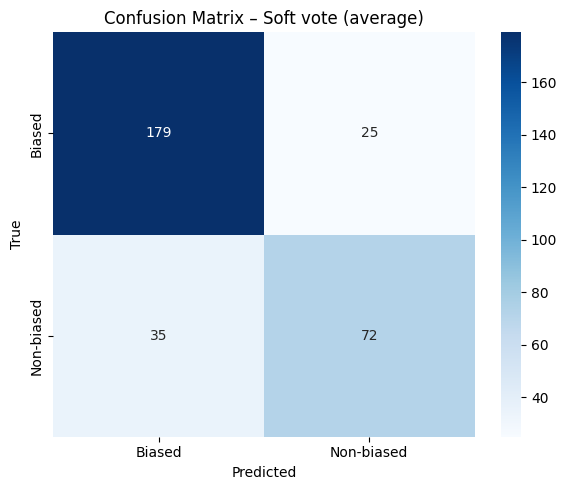


Best DeBERTa weight on VALIDATION: w=0.80 (val macro-F1=0.8339)

=== Weighted vote (w=0.80, chosen on val) ===
Accuracy: 0.797427652733119
Macro-F1: 0.7740685647075103
              precision    recall  f1-score   support

      Biased       0.84      0.85      0.85       204
  Non-biased       0.71      0.69      0.70       107

    accuracy                           0.80       311
   macro avg       0.78      0.77      0.77       311
weighted avg       0.80      0.80      0.80       311



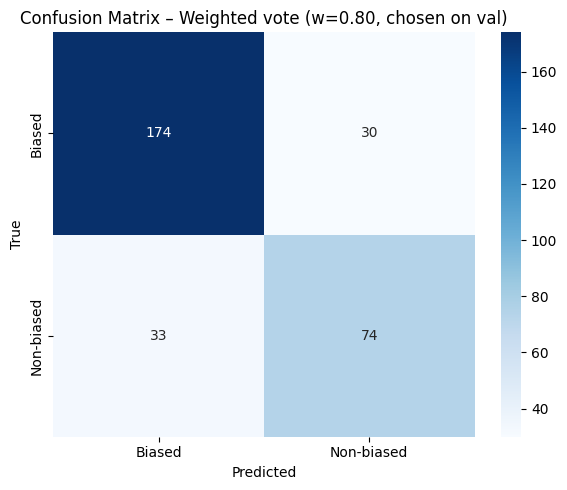


=== Stacking (fitted on val) ===
Accuracy: 0.819935691318328
Macro-F1: 0.8053991239831948
              precision    recall  f1-score   support

      Biased       0.89      0.83      0.86       204
  Non-biased       0.71      0.79      0.75       107

    accuracy                           0.82       311
   macro avg       0.80      0.81      0.81       311
weighted avg       0.83      0.82      0.82       311



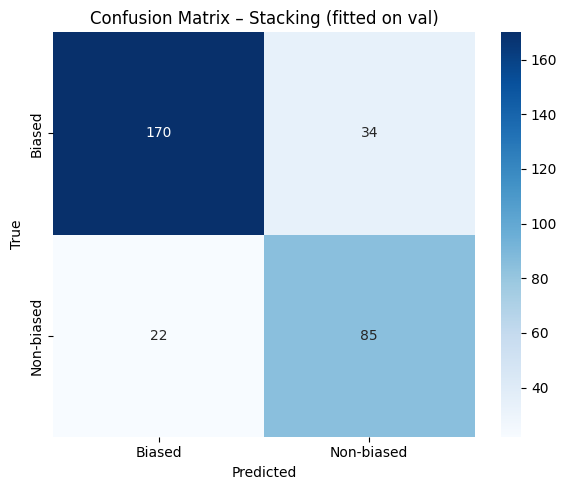

In [13]:
# =========================
# ENSEMBLE: tuned DeBERTa + RoBERTa-large
# The voting weight and the stacking model are fitted on VALIDATION predictions.
# The TEST set is only used for the final scores.
# =========================
import gc
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEBERTA_DIR = "/content/model_deberta"        # saved by the "Tuned DeBERTa" cell
ROBERTA_DIR = "/content/model_roberta_large"  # saved by the RoBERTa-large cell
MAX_LEN = 256                                 # sentences are at most ~130 tokens

# Both models must have been trained with the current settings (same input + same split)
for d in (DEBERTA_DIR, ROBERTA_DIR):
    check_run_info(d)

X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
y_val, y_test = np.array(y_val), np.array(y_test)
print(f"Val: {len(X_val)} | Test: {len(X_test)} | split id: {SPLIT_ID} | words in input: {USE_BIASED_WORDS}")

# -------------------------
# Predict probabilities on val + test (one model in memory at a time)
# -------------------------
@torch.no_grad()
def predict_proba(model_dir, texts, batch_size=32):
    tok = AutoTokenizer.from_pretrained(model_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_dir, dtype=torch.float32).to(device)
    mdl.eval()
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], truncation=True, padding=True,
                  max_length=MAX_LEN, return_tensors="pt").to(device)
        out.append(torch.softmax(mdl(**enc).logits.float(), dim=1).cpu().numpy())
    del mdl
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.vstack(out)

n_val = len(X_val)
p = predict_proba(DEBERTA_DIR, X_val + X_test)
deb_val, deb_test = p[:n_val], p[n_val:]
p = predict_proba(ROBERTA_DIR, X_val + X_test, batch_size=16)
rob_val, rob_test = p[:n_val], p[n_val:]

def evaluate_probs(probs, title, record=False):
    y_pred = probs.argmax(axis=1)
    print(f"\n=== {title} ===")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Macro-F1:", f1_score(y_test, y_pred, average="macro"))
    print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix – {title}")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.show()
    if record:
        record_result(f"Ensemble: {title}", y_test, y_pred)

# -------------------------
# 0) Do the two models actually disagree? If they almost never do, ensembling cannot help.
# -------------------------
agree = (deb_test.argmax(1) == rob_test.argmax(1)).mean()
print(f"\nDeBERTa and RoBERTa give the same label on {agree:.1%} of test sentences.")

# 1) Individual models (re-loaded from disk)
evaluate_probs(deb_test, "DeBERTa (loaded)")
evaluate_probs(rob_test, "RoBERTa-large (loaded)")

# 2) Soft voting: simple average, nothing tuned
evaluate_probs((deb_test + rob_test) / 2.0, "Soft vote (average)", record=True)

# 3) Weighted soft voting: weight chosen on VALIDATION (ties -> the weight closest to 0.5)
cands = []
for w in np.linspace(0.0, 1.0, 21):
    f1v = f1_score(y_val, (w * deb_val + (1 - w) * rob_val).argmax(1), average="macro")
    cands.append((round(f1v, 6), -abs(w - 0.5), w))
best_f1_val, _, best_w = max(cands)
print(f"\nBest DeBERTa weight on VALIDATION: w={best_w:.2f} (val macro-F1={best_f1_val:.4f})")
evaluate_probs(best_w * deb_test + (1 - best_w) * rob_test, f"Weighted vote (w={best_w:.2f}, chosen on val)", record=True)

# 4) Stacking: logistic regression fitted on VALIDATION probabilities
#    (rows neither model was trained on, so the meta-model sees honest predictions)
meta = LogisticRegression(max_iter=2000, class_weight="balanced")
meta.fit(np.hstack([deb_val, rob_val]), y_val)
evaluate_probs(meta.predict_proba(np.hstack([deb_test, rob_test])), "Stacking (fitted on val)", record=True)

## Results summary
Every model cell run in this session, scored on the same test sentences.

In [14]:
import pandas as pd
summary = pd.DataFrame(RESULTS).T.sort_values("macro_f1", ascending=False)
summary["n_test"] = summary["n_test"].astype(int)
print(f"Test sentences: {len(idx_test)} | split id: {SPLIT_ID}")
print(summary.to_string())

Test sentences: 311 | split id: 3d637336
                                                             accuracy  macro_f1  n_test
DeBERTa-v3-base (plain) | words=off                            0.8553    0.8379     311
DeBERTa-v3-base (label smoothing) | words=off                  0.8296    0.8099     311
Ensemble: Stacking (fitted on val) | words=off                 0.8199    0.8054     311
RoBERTa-large | words=off                                      0.8232    0.7989     311
Ensemble: Soft vote (average) | words=off                      0.8071    0.7812     311
Ensemble: Weighted vote (w=0.80, chosen on val) | words=off    0.7974    0.7741     311
DeBERTa-v3-base (tuned) | words=off                            0.7910    0.7669     311
TF-IDF + LinearSVC | words=off                                 0.7170    0.6837     311


In [15]:
# Check: load the SAVED model from Drive and score a neutral and a loaded sentence
import torch, transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SAVE_DIR_PLAIN = "/content/drive/MyDrive/truthlens/model_deberta_plain"
tok = AutoTokenizer.from_pretrained(SAVE_DIR_PLAIN)
mdl = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR_PLAIN).float().eval()

sentences = ["The minister announced the budget on Monday.",
             "The corrupt minister shamelessly rammed through his disastrous budget."]
with torch.no_grad():
    probs = torch.softmax(mdl(**tok(sentences, return_tensors="pt", padding=True)).logits, -1)

print(mdl.config.id2label)
for s, p in zip(sentences, probs):
    print(f"{p[0].item():.2f} Biased | {s}")
print("transformers version:", transformers.__version__)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{0: 'Biased', 1: 'Non-biased'}
0.14 Biased | The minister announced the budget on Monday.
0.98 Biased | The corrupt minister shamelessly rammed through his disastrous budget.
transformers version: 5.21.0
